## Analitika kitabxanalarının yüklənməsi

#### İstifadə olunacaq numpy, pandas, matplotlib və seaborn kitabxanalarını gətirin

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Datasetin Yüklənməsi

#### Dataseti yükləyin

In [2]:
df=pd.read_csv(r"C:\Users\PC\Downloads\netflix daily top 10.csv")

## Dataset Məlumatları

#### Datasetlə tanış olun və ilk 10 dəyərinə göz gəzdirin

In [5]:
df

,As of,Rank,Year to Date Rank,Last Week Rank,Title,Type,Netflix Exclusive,Netflix Release Date,Days In Top 10,Viewership Score
0,2020-04-01,1,1,1,"Tiger King: Murder, Mayhem …",TV Show,Yes,"Mar 20, 2020",9,90
1,2020-04-01,2,2,-,Ozark,TV Show,Yes,"Jul 21, 2017",5,45
2,2020-04-01,3,3,2,All American,TV Show,NaN,"Mar 28, 2019",9,76
3,2020-04-01,4,4,-,Blood Father,Movie,NaN,"Mar 26, 2020",5,30
4,2020-04-01,5,5,4,The Platform,Movie,Yes,"Mar 20, 2020",9,55
...,...,...,...,...,...,...,...,...,...,...
7095,2022-03-11,6,5,1,Worst Roommate Ever,TV Show,Yes,"Mar 1, 2022",10,81
7096,2022-03-11,7,7,2,Vikings: Valhalla,TV Show,Yes,"Feb 25, 2022",14,100
7097,2022-03-11,8,8,-,Shooter,Movie,NaN,"Aug 1, 2014",3,7
7098,2022-03-11,9,9,7,Shrek 2,Movie,NaN,"Mar 1, 2022",10,33


#### Dataset haqqında məlumat əldə edə biləcəyiniz kodları yazın. Dataset neçə sətrdən ibarətdir, hansı sütunları var, sütunların tipləri nələrdir?

In [6]:
df.info()
# Datasetin sətir və sütun sayı
print("Sətir və sütun sayı:",df.shape)
# Sütunlar və onların tipləri
df.dtypes

<class 'pandas.DataFrame'>
RangeIndex: 7100 entries, 0 to 7099
Data columns (total 10 columns):
 #   Column                Non-Null Count  Dtype
---  ------                --------------  -----
 0   As of                 7100 non-null   str  
 1   Rank                  7100 non-null   int64
 2   Year to Date Rank     7100 non-null   str  
 3   Last Week Rank        7100 non-null   str  
 4   Title                 7100 non-null   str  
 5   Type                  7100 non-null   str  
 6   Netflix Exclusive     4599 non-null   str  
 7   Netflix Release Date  7100 non-null   str  
 8   Days In Top 10        7100 non-null   int64
 9   Viewership Score      7100 non-null   int64
dtypes: int64(3), str(7)
memory usage: 877.6 KB
Sətir və sütun sayı: (7100, 10)


As of                     str
Rank                    int64
Year to Date Rank         str
Last Week Rank            str
Title                     str
Type                      str
Netflix Exclusive         str
Netflix Release Date      str
Days In Top 10          int64
Viewership Score        int64
dtype: object

## Data Wrangling

#### Datanın sütunları ilə tanış olun. Onlar hansı data tiplərindədir? Bütün sütunların data tipləri uyğundur?

In [7]:
# Sütunlar və onların tipləri
df.dtypes
# Xeyr, As of və Netflix Release Date tarix məlumatları olmasına baxmayaraq mətn tipindədirlər. Həmçinin Year to Date Rank və Last Week reytinq sütunu olmasına baxmayaraq str tipindədir.

As of                     str
Rank                    int64
Year to Date Rank         str
Last Week Rank            str
Title                     str
Type                      str
Netflix Exclusive         str
Netflix Release Date      str
Days In Top 10          int64
Viewership Score        int64
dtype: object

#### Düzgün data tipində olmayan müvafiq data tiplərinə keçirin

In [8]:
# Tarix sütunlarını datetime formatına çeviririk
df['As of'] = pd.to_datetime(df['As of'])
df['Netflix Release Date'] = pd.to_datetime(df['Netflix Release Date'])
# Reytinq sütunlarını number formatına çeviririk
df['Year to Date Rank'] = pd.to_numeric(df['Year to Date Rank'], errors='coerce')
df['Last Week Rank'] = pd.to_numeric(df['Last Week Rank'], errors='coerce')

#### Hansı sütunlarda boş sətrlər var? Hansı sütunlarda neçə boş sətr var?

In [9]:
df.isnull().sum()

As of                      0
Rank                       0
Year to Date Rank        859
Last Week Rank          3968
Title                      0
Type                       0
Netflix Exclusive       2501
Netflix Release Date       0
Days In Top 10             0
Viewership Score           0
dtype: int64

#### Boş sətrlər olan sütunda olan bütün boş məlumatları "No" yazısı ilə doldurun

In [21]:
df.fillna('No', inplace=True)

,As of,Rank,Year to Date Rank,Last Week Rank,Title,Type,Netflix Exclusive,Netflix Release Date,Days In Top 10,Viewership Score
0,2020-04-01,1,1.0,1.0,"Tiger King: Murder, Mayhem …",TV Show,Yes,2020-03-20,9,90
1,2020-04-01,2,2.0,No,Ozark,TV Show,Yes,2017-07-21,5,45
2,2020-04-01,3,3.0,2.0,All American,TV Show,No,2019-03-28,9,76
3,2020-04-01,4,4.0,No,Blood Father,Movie,No,2020-03-26,5,30
4,2020-04-01,5,5.0,4.0,The Platform,Movie,Yes,2020-03-20,9,55
...,...,...,...,...,...,...,...,...,...,...
7095,2022-03-11,6,5.0,1.0,Worst Roommate Ever,TV Show,Yes,2022-03-01,10,81
7096,2022-03-11,7,7.0,2.0,Vikings: Valhalla,TV Show,Yes,2022-02-25,14,100
7097,2022-03-11,8,8.0,No,Shooter,Movie,No,2014-08-01,3,7
7098,2022-03-11,9,9.0,7.0,Shrek 2,Movie,No,2022-03-01,10,33


## Analysis

#### Datada film tiplərinə görə paylanmanı göstərmək üçün pie chart-dan istifadə edin

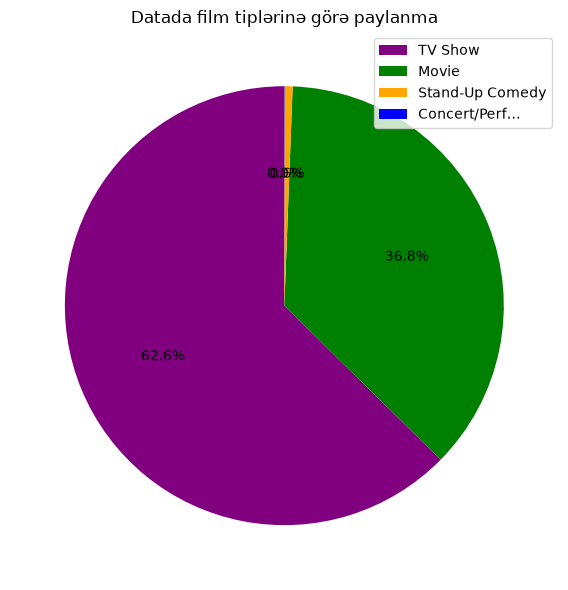

In [37]:
# Type sütunundakı kateqoriyaların sayını hesablayaq
type_counts = df['Type'].value_counts()

# Pie chart qururuq
type_counts = df['Type'].value_counts()
plt.figure(figsize=(6,6))
plt.pie(df['Type'].value_counts(),autopct='%1.1f%%', startangle=90, colors = ['purple','green','orange','blue'])
plt.title('Datada film tiplərinə görə paylanma')
plt.ylabel('')
plt.legend(type_counts.index, loc="upper right")
plt.tight_layout()
plt.show()

#### Ən çox hansı filmlər ilk 10 film arasına girib?

In [25]:
df['Title'].value_counts().head(10)

Title
Cocomelon               428
Ozark                    85
Cobra Kai                81
Manifest                 80
The Queenâs Gambit     73
Outer Banks              72
Squid Game               66
All American             58
Bridgerton               58
Lucifer                  56
Name: count, dtype: int64

#### İstifadəçi reytinqlərinə görə ən yüksək 10 film hansıdır? Nəticəni vizuallaşdırın

C:\Users\PC\AppData\Local\Temp\ipykernel_7764\3464217361.py:9: UserWarning: Glyph 128 (\x80) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\PC\AppData\Local\Temp\ipykernel_7764\3464217361.py:9: UserWarning: Glyph 153 (\x99) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\PC\Documents\New folder\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 128 (\x80) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\PC\Documents\New folder\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 153 (\x99) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


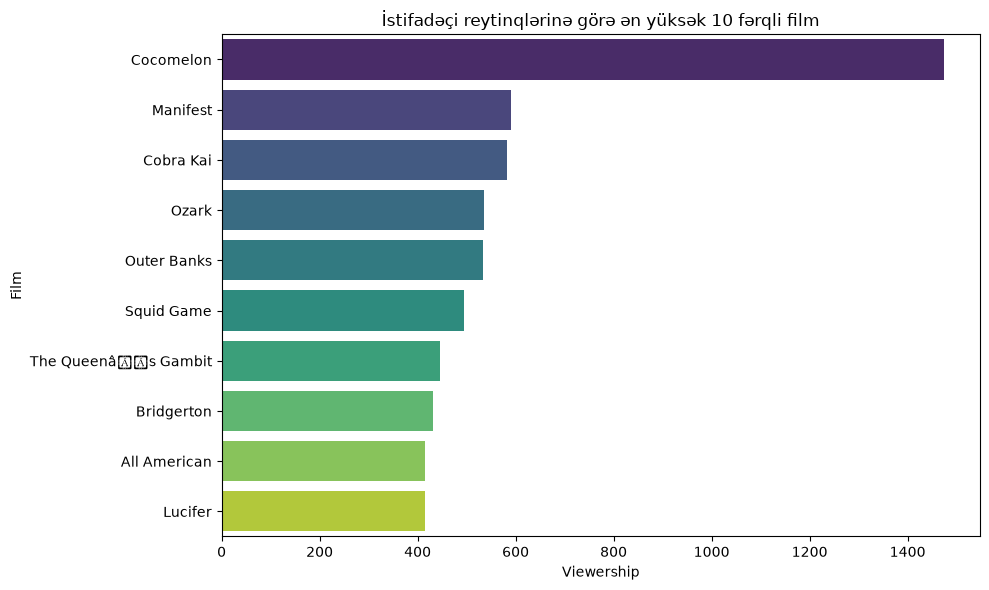

In [29]:
top_10_movies = df.groupby('Title')['Viewership Score'].max().reset_index()
top_10_movies = top_10_movies.sort_values(by='Viewership Score', ascending=False).head(10)

plt.figure(figsize=(10,6))
sns.barplot(x='Viewership Score', y='Title', data=top_10_movies, palette='viridis', hue='Title', legend=False)
plt.title('İstifadəçi reytinqlərinə görə ən yüksək 10 fərqli film')
plt.xlabel('Viewership')
plt.ylabel('Film')
plt.tight_layout()
plt.show()

#### Ən çox birinci yerdə qalan filmi öyrənmək istəyirəm

In [36]:
top_first_place = df[df['Rank'] == 1]['Title'].value_counts().head(1)
print(top_first_place)

Title
Cobra Kai    27
Name: count, dtype: int64


#### Neçə fərqli gün üçün aparılıb bu ölçümlər? Yəni neçə fərqli gün üçün top 10 film göstərilib?

In [37]:
unique_days_count = df['As of'].nunique()
print(f"Fərqli günlərin sayı: {unique_days_count}")

Fərqli günlərin sayı: 710


#### Netflix Exclusive filmlər daha yüksək reytinqə sahibdir, yoxsa digərləri?

In [32]:
result = df.groupby('Netflix Exclusive')['Viewership Score'].mean()
print(result)

Netflix Exclusive
No     185.542583
Yes     88.664492
Name: Viewership Score, dtype: float64


#### Mən TV Show və Movie lər üçün aylıq trendi görmək istəyirəm.

#### Mən filmin Netflix-də yayınlanma tarixi ilə hər hansı bir korrelyasiyaya sahib olub olmadığını öyrənmək istəyirəm. Bunu həm düsturla, həm də vizualizasiya ilə göstərməlisiniz

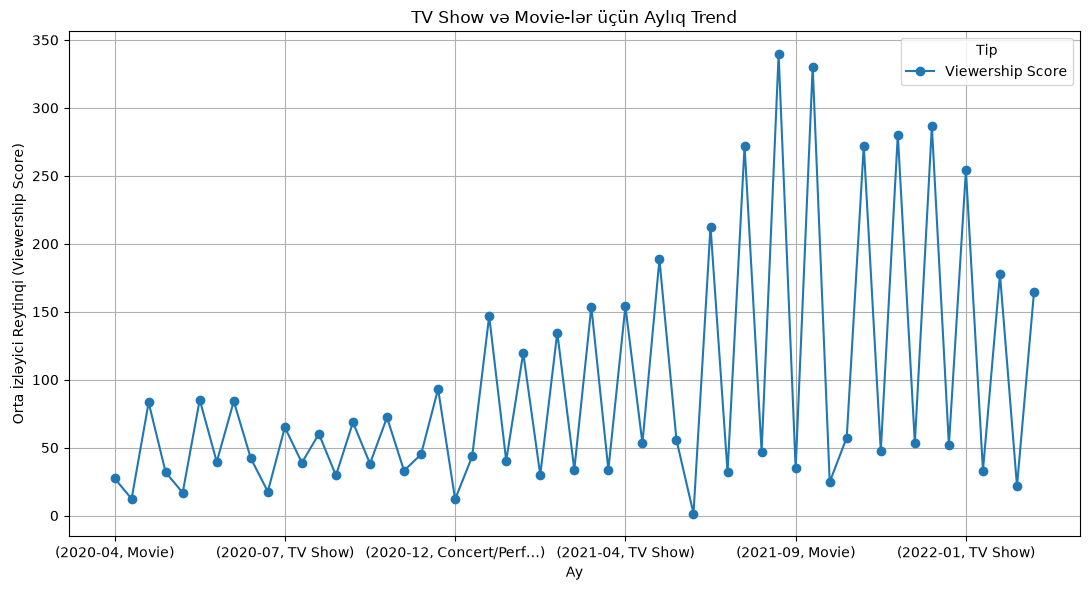

In [40]:
# 'As of' sütununu tarix formatına çeviririk və ayı (Month) əldə edirik
df['As of'] = pd.to_datetime(df['As of'])
df['Month'] = df['As of'].dt.to_period('M')

# Type və Ay üzrə qruplaşdırıb, məlumatı qrafikə uyğun hazırlayırıq
monthly_trend = df.groupby(['Month', 'Type'])['Viewership Score'].mean()

# Vizuallaşdırma (Xətt qrafiki)
plt.figure(figsize=(11, 6))
monthly_trend.plot(kind='line', marker='o')
plt.title('TV Show və Movie-lər üçün Aylıq Trend')
plt.xlabel('Ay')
plt.ylabel('Orta İzləyici Reytinqi (Viewership Score)')
plt.grid(True)
plt.legend(title='Tip')
plt.tight_layout()
plt.show()

#### Yuxarıdakı xətaya əsasən, aşağıda təkcə illərə görə yeni bir korrelyasiya əmsalı hesablayın

In [41]:
# "Netflix Release" Date sütunundan yalnız ili çıxarıb yeni sütun yaradırıq
df['Release_Year'] = pd.to_datetime(df['Netflix Release Date']).dt.year

# Təkcə illərə görə "Viewership Score" ilə korrelasiya əmsalını hesablayırıq
correlation_by_year = df['Release_Year'].corr(df['Viewership Score'])
print(f"İllərə görə yayınlanma tarixi ilə Viewership Score arasında korrelasiya: {correlation_by_year}")

İllərə görə yayınlanma tarixi ilə Viewership Score arasında korrelasiya: -0.03128620515242002


#### Aylara görə ən məşhur Filmlər hansı olub?

In [28]:
# "Netflix Release" Date sütunundan ayı çıxarıb yeni sütun yaradırıq
df['Release_Month'] = pd.to_datetime(df['Netflix Release Date']).dt.month

# Hər ay üzrə maksimum "Viewership Score" olan sətrin indeksini tapırıq
idx = df.groupby('Release_Month')['Viewership Score'].idxmax()

# Həmin indekslərə uyğun filmləri çıxarırıq
top_movies_by_month = df.loc[idx, ['Release_Month', 'Title', 'Viewership Score']]
print(top_movies_by_month)

      Release_Month                 Title  Viewership Score
5489              1         The Circle US               213
3949              2       Ginny & Georgia               335
5209              3          All American               416
5187              4           Outer Banks               534
7008              5       Sweet Magnolias               344
6998              6             Cocomelon              1474
6996              7                 Ozark               536
6678              8             Cobra Kai               582
6068              9            Squid Game               495
2809             10  The Queenâs Gambit               446
6439             11     The Queen of Flow               250
3269             12            Bridgerton               432


#### 1/2/3/4 rübdə ən yüksək izləyici reytinqi olan 5 film hansı olub?

In [45]:
# Tarixdən rüb sütununu yaradırıq
df['Quarter'] = pd.to_datetime(df['Netflix Release Date']).dt.quarter

# Hər rüb üzrə "Viewership Score"-a görə ən yüksək olan 5 filmi tapırıq
top5_per_quarter = (df.sort_values(['Quarter', 'Viewership Score'], ascending=[True, False]).groupby('Quarter').head(5))

# Lazımi sütunları ekrana çıxarırıq
top5_per_quarter[['Quarter', 'Title', 'Viewership Score']]

,Quarter,Title,Viewership Score
5209,1,All American,416
5198,1,All American,415
5185,1,All American,413
5175,1,All American,408
5169,1,All American,403
6998,2,Cocomelon,1474
6959,2,Cocomelon,1472
6718,2,Cocomelon,1471
6687,2,Cocomelon,1469
6674,2,Cocomelon,1466


#### Yeni bir dashboard yaradın (15,15 ölçüsündə). Ən önəmli gördüyünüz 4 ədəd vizualı bu dashboard-da göstərin

C:\Users\PC\AppData\Local\Temp\ipykernel_7764\1929688286.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Type', palette='Set2')
C:\Users\PC\AppData\Local\Temp\ipykernel_7764\1929688286.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top10, x='Viewership Score', y='Title', palette='viridis')
C:\Users\PC\AppData\Local\Temp\ipykernel_7764\1929688286.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Quarter', y='Viewership Score', palette='Pastel1')


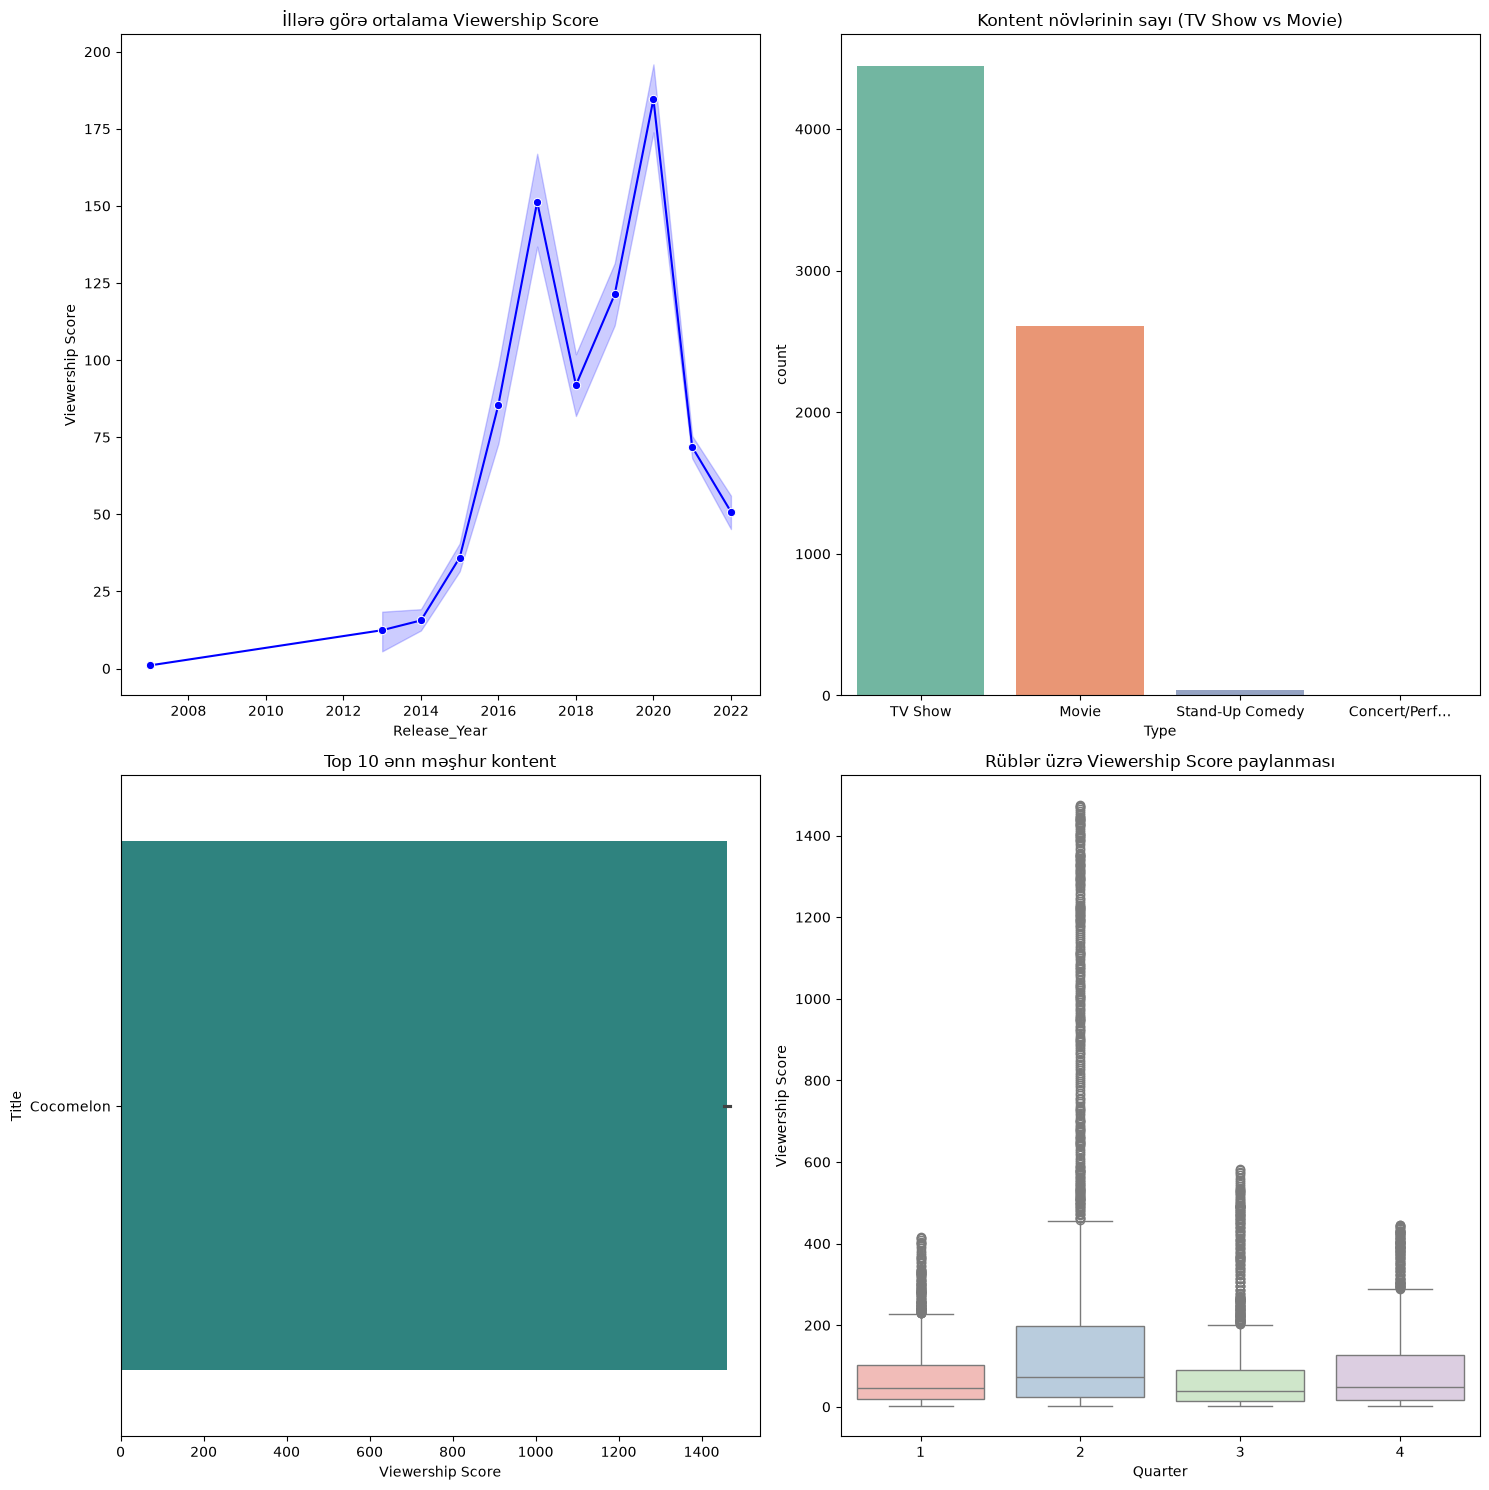

In [46]:
plt.figure(figsize=(15, 15))

# İllərə görə ortalama Viewership Score
plt.subplot(2, 2, 1)
sns.lineplot(data=df, x='Release_Year', y='Viewership Score', marker='o', color='b')
plt.title('İllərə görə ortalama Viewership Score')

# Növə görə kontent paylanması
plt.subplot(2, 2, 2)
sns.countplot(data=df, x='Type', palette='Set2')
plt.title('Kontent növlərinin sayı (TV Show vs Movie)')

# Top 10 Ən Yüksək Reytinqli Kontent
plt.subplot(2, 2, 3)
top10 = df.sort_values(by='Viewership Score', ascending=False).head(10)
sns.barplot(data=top10, x='Viewership Score', y='Title', palette='viridis')
plt.title('Top 10 ənn məşhur kontent')

# Rüblər üzrə Viewership Score paylanması
plt.subplot(2, 2, 4)
sns.boxplot(data=df, x='Quarter', y='Viewership Score', palette='Pastel1')
plt.title('Rüblər üzrə Viewership Score paylanması')

plt.tight_layout()
plt.show()